# Telco Customer Churn: Cleaning, Exploration, Segmentation and Advanced Analysis

**Author:** Odetunde Olumide Temitope  |  **Date:** 28 October 2026
**Program:** Business Analysis Internship, SaiKet Systems (project: *Customer Segmentation Visualization & Advanced Analysis*)

**Goal.** Analyze customer churn in a telecommunications company, find which customers are most at risk, and turn the findings into recommendations that reduce churn.

**Dataset.** `Telco_Customer_Churn_Dataset (3).csv`: 7,043 customers x 21 columns. Each row is one customer. The target column is `Churn` (Yes / No).

| Section | Task | What it covers |
|---|---|---|
| 1 | Task 1 | Load the data and inspect it |
| 2 | Task 2 | Clean the data (names, blanks, duplicates, types, target) |
| 3 | Task 3 | Exploratory analysis: statistics, distributions, churn rate |
| 4 | Task 4 | Customer segmentation by tenure (donut and clustered bar charts) |
| 5 | Task 5 | Advanced analysis: churn by tenure group, demographics, payment, contract, lifecycle |
| 6 | | Summary of findings |

**How to run.** Place the CSV in the same folder as this notebook, then use *Restart Kernel and Run All*. Run the cells in order: later cells rely on columns created earlier (for example `tenure_segment`), and the churn column is encoded to 0/1 only once.

**Libraries.** pandas, numpy, matplotlib, seaborn, scipy. If one is missing, install it inside the notebook with `%pip install <name>` and restart the kernel.

**Naming used throughout.** `df` is the raw data, `df_clean` is the cleaned copy used for all analysis, and in `churn` **1 = churned, 0 = stayed**.

## 1. Load and inspect the data (Task 1)

Goal: get familiar with the dataset before changing anything. We load it, look at the first rows, check each column's data type, and count missing values.

In [1]:
import pandas as pd
import numpy as np

Load the CSV into a DataFrame called `df`. The file must be in the same folder as the notebook (note the two spaces in the file name).

In [2]:
df = pd.read_csv("Telco_Customer_Churn_Dataset  (3).csv")

Look at the first 10 rows to see what each column contains and how values are written (Yes/No, categories, numbers).

In [3]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


Check the data type and non-null count of every column.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Finding.** 7,043 rows and 21 columns, with no column reporting missing values. One problem stands out: `TotalCharges` is stored as text (`str`) although it holds money amounts. This is investigated in Section 2.

Count missing values per column.

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

**Finding.** Zero missing values everywhere. This result cannot be fully trusted for `TotalCharges`: blank cells holding a single space are not counted as missing by `isnull()`. Section 2 shows 11 hidden blanks.

## Data Cleaning

## 2. Data cleaning (Task 2)

Goal: make the dataset safe to analyze: standardized column names, hidden blanks found, duplicates checked, correct data types, and a numeric target.

**Approach.** All cleaning is done on a copy (`df_clean`), so the original `df` stays untouched. Steps run in a deliberate order: whitespace is trimmed *before* placeholders are converted to missing values, and `totalcharges` is converted to numbers *before* the generic fill rules, otherwise the hidden blanks would be skipped.

Step 0: make a working copy and record the starting shape.

In [6]:
df_clean = df.copy()
print("Original shape:", df_clean.shape)

Original shape: (7043, 21)


**Step 1: standardize column names.** Trim spaces, convert to lowercase, remove special characters and replace spaces with underscores (for example `customerID` becomes `customerid`).

In [7]:
# 1. Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip().str.lower()
    .str.replace(r"[^\w\s]", "", regex=True)
    .str.replace(r"\s+", "_", regex=True)
)

**Step 2: trim whitespace first, then convert placeholders to missing values.** The order matters: a cell containing only a space becomes an empty string after trimming, and is then converted to NaN together with `?`, `N/A`, `-`, and similar placeholders.

In [8]:
# 2. FIX: trim whitespace FIRST, then convert placeholders to NaN
#    (so a blank " " becomes "" and is caught)
text_cols = df_clean.select_dtypes(include=["object", "str"]).columns
for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()
df_clean = df_clean.replace(["?", "N/A", "n/a", "NA", "-", "", "null", "None"], np.nan)


**Step 3: fix `totalcharges`.** Convert it to numbers; entries that are not numbers become NaN. Then check that every blank belongs to a customer with `tenure == 0` (a brand-new customer who has not been billed yet). If so, filling with 0 is accurate. A median fill would invent charges that never happened.

In [9]:
# 3. FIX: convert totalcharges to numeric BEFORE the generic fill step
df_clean["totalcharges"] = pd.to_numeric(df_clean["totalcharges"], errors="coerce")

blank = df_clean["totalcharges"].isnull()
print("Blank totalcharges:", blank.sum())                      # 11
print("All have tenure 0:", (df_clean.loc[blank, "tenure"] == 0).all())  # True
df_clean.loc[blank, "totalcharges"] = 0 

Blank totalcharges: 11
All have tenure 0: True


**Result.** 11 blank values were found and all 11 have tenure 0, so they were filled with 0.

**Step 4: duplicates.** Check for repeated rows and confirm each `customerid` appears only once, then drop any duplicate rows.

In [10]:
# 4. Duplicates (full rows, and by customer ID)
print("Duplicate rows:", df_clean.duplicated().sum())
print("customerid unique:", df_clean["customerid"].is_unique)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

Duplicate rows: 0
customerid unique: True


**Result.** 0 duplicate rows and `customerid` is unique, so nothing was removed.

**Step 5: remaining missing values.** Drop columns that are more than 50% empty, fill numeric columns with the median and text columns with the most frequent value. Nothing needed dropping here, so these rules act as a safety net.

In [11]:
# 5. Remaining missing values
mostly_empty = df_clean.columns[df_clean.isnull().mean() > 0.5]
df_clean = df_clean.drop(columns=mostly_empty)
print("Dropped columns:", list(mostly_empty))

for col in df_clean.select_dtypes(include=np.number).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include=["object", "str", "category"]).columns:
    if df_clean[col].notna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])


Dropped columns: []


**Step 6: consistency check.** Print the unique values of every text column to catch spelling variants such as `yes` versus `Yes`.

In [12]:
# 6. FIX: check text columns for inconsistent spellings
for col in df_clean.select_dtypes(include=["object", "str"]).columns:
    if col != "customerid":
        print(f"{col}: {sorted(df_clean[col].unique())}")

gender: ['Female', 'Male']
partner: ['No', 'Yes']
dependents: ['No', 'Yes']
phoneservice: ['No', 'Yes']
multiplelines: ['No', 'No phone service', 'Yes']
internetservice: ['DSL', 'Fiber optic', 'No']
onlinesecurity: ['No', 'No internet service', 'Yes']
onlinebackup: ['No', 'No internet service', 'Yes']
deviceprotection: ['No', 'No internet service', 'Yes']
techsupport: ['No', 'No internet service', 'Yes']
streamingtv: ['No', 'No internet service', 'Yes']
streamingmovies: ['No', 'No internet service', 'Yes']
contract: ['Month-to-month', 'One year', 'Two year']
paperlessbilling: ['No', 'Yes']
paymentmethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
churn: ['No', 'Yes']


**Result.** No spelling variants. Values such as *No phone service* and *No internet service* are real categories, not errors, so they are kept.

**Step 7: encode the target.** Map `churn` from Yes/No to 1/0 so it can be averaged (the mean of a 0/1 column is the churn rate). Run this cell **only once**: running it again would turn the column into NaN.

In [13]:
# 7. FIX: encode churn, then show the class counts directly
df_clean["churn"] = df_clean["churn"].map({"Yes": 1, "No": 0})
print("\nChurn counts:\n", df_clean["churn"].value_counts())
print("\nChurn %:\n", (df_clean["churn"].value_counts(normalize=True) * 100).round(1))


Churn counts:
 churn
0    5174
1    1869
Name: count, dtype: int64

Churn %:
 churn
0    73.5
1    26.5
Name: proportion, dtype: float64


**Result.** 5,174 customers stayed (73.5%) and 1,869 churned (26.5%). The classes are imbalanced, which matters for any later predictive model.

**Step 8: final verification** of missing values, duplicates, shape and data types.

In [14]:
# 8. Final verification
print("\nMissing:", df_clean.isnull().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())
print("Shape:", df_clean.shape)
df_clean.info()


Missing: 0
Duplicates: 0
Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   seniorcitizen     7043 non-null   int64  
 3   partner           7043 non-null   str    
 4   dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   phoneservice      7043 non-null   str    
 7   multiplelines     7043 non-null   str    
 8   internetservice   7043 non-null   str    
 9   onlinesecurity    7043 non-null   str    
 10  onlinebackup      7043 non-null   str    
 11  deviceprotection  7043 non-null   str    
 12  techsupport       7043 non-null   str    
 13  streamingtv       7043 non-null   str    
 14  streamingmovies   7043 non-null   str    
 15  contract          7043 non-null   str    
 16  paperless

**Cleaning result.** Shape (7043, 21), 0 missing values, 0 duplicates, lowercase column names, `totalcharges` is now numeric (float64) and `churn` is numeric (int64). The data is ready for analysis.

## 3. Exploratory data analysis (Task 3)

Goal: understand the distributions and typical values in the data, and measure how much churn there is.

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

**Summary statistics** (mean, median, mode, spread) for the three numeric columns. Comparing mean with median shows skew.

In [16]:
sns.set_theme(style="whitegrid")
num_cols = ["tenure", "monthlycharges", "totalcharges"]
summary = pd.DataFrame({
    "mean":   df_clean[num_cols].mean(),
    "median": df_clean[num_cols].median(),
    "mode":   df_clean[num_cols].mode().iloc[0],
    "std":    df_clean[num_cols].std(),
    "min":    df_clean[num_cols].min(),
    "max":    df_clean[num_cols].max(),
}).round(2)
summary

,mean,median,mode,std,min,max
tenure,32.37,29.00,1.00,24.56,0.00,72.00
monthlycharges,64.76,70.35,20.05,30.09,18.25,118.75
totalcharges,2279.73,1394.55,0.00,2266.79,0.00,8684.80


**Finding.**
- `tenure`: mean 32.4, median 29, mode 1 month. Many customers are very new.
- `monthlycharges`: mean 64.76 is below the median 70.35, and the mode is about 20, a large group on the cheapest plans.
- `totalcharges`: mean 2,279.73 is far above the median 1,394.55 (right-skewed); the mode of 0 comes from the 11 new customers.

Full descriptive table, including quartiles, for all numeric columns.

In [17]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
seniorcitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
monthlycharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
totalcharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80
churn,7043.0,0.265370,0.441561,0.00,0.00,0.00,1.00,1.00


**Most common value (mode) of each text column**, which describes the most typical customer.

In [18]:
cat_cols = df_clean.select_dtypes(include=["object", "str"]).columns.drop("customerid")
df_clean[cat_cols].mode().iloc[0]

gender                          Male
partner                           No
dependents                        No
phoneservice                     Yes
multiplelines                     No
internetservice          Fiber optic
onlinesecurity                    No
onlinebackup                      No
deviceprotection                  No
techsupport                       No
streamingtv                       No
streamingmovies                   No
contract              Month-to-month
paperlessbilling                 Yes
paymentmethod       Electronic check
Name: 0, dtype: str

**Finding.** The most common customer has fiber optic internet, a month-to-month contract, paperless billing and pays by electronic check, with no online security, backup, device protection or tech support. Note that month-to-month and electronic check are also the two groups with the highest churn (Section 5).

**Histograms** of the numeric columns. The red dashed line is the mean and the green line is the median.

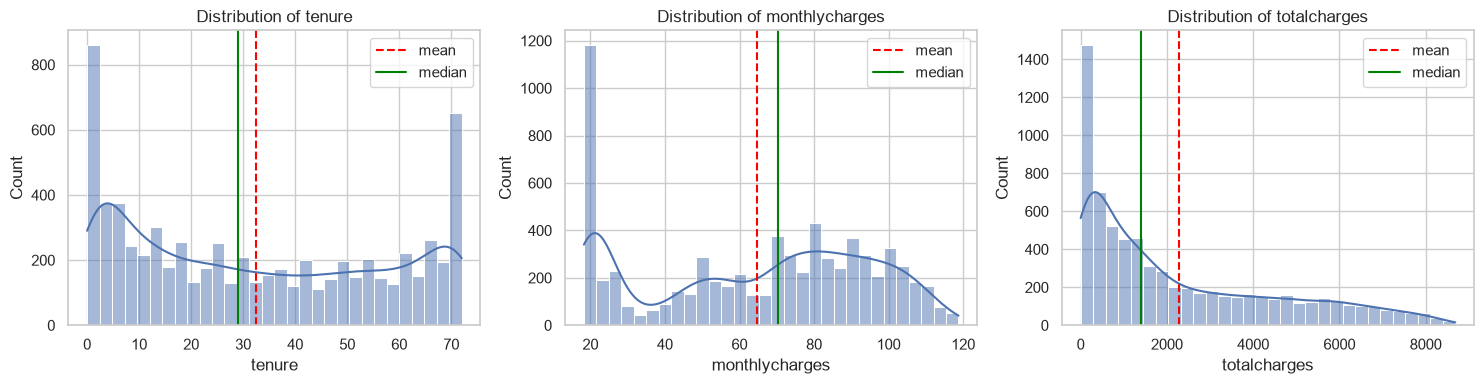

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df_clean[col], bins=30, kde=True, ax=ax)
    ax.axvline(df_clean[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(df_clean[col].median(), color="green", linestyle="-", label="median")
    ax.set_title(f"Distribution of {col}")
    ax.legend()
plt.tight_layout()
plt.show()

**Finding.** `tenure` is U-shaped, with spikes at the very start (new customers) and at 72 months (loyal customers). `monthlycharges` has a large spike near 20 and a broader hump around 80-100. `totalcharges` is strongly right-skewed, as expected since it grows with tenure.

**Box plots** to see spread and outliers.

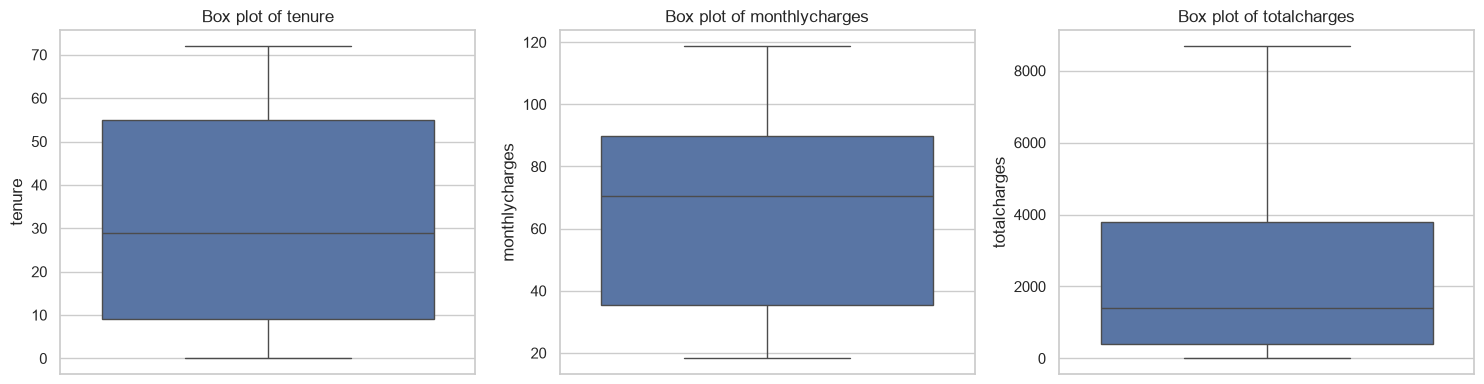

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f"Box plot of {col}")
plt.tight_layout()
plt.show()

**Finding.** No outliers are flagged in the overall box plots. The values are all plausible (tenure 0-72, monthly charges 18-119), so nothing was removed.

**Numeric columns split by churn**, with medians per group. This shows how churned customers differ from those who stayed. (The `set_ticklabels` warning is harmless and only concerns axis labels.)

C:\Users\User\AppData\Local\Temp\ipykernel_20688\3428050619.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
C:\Users\User\AppData\Local\Temp\ipykernel_20688\3428050619.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
C:\Users\User\AppData\Local\Temp\ipykernel_20688\3428050619.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stayed (0)", "Churned (1)"])


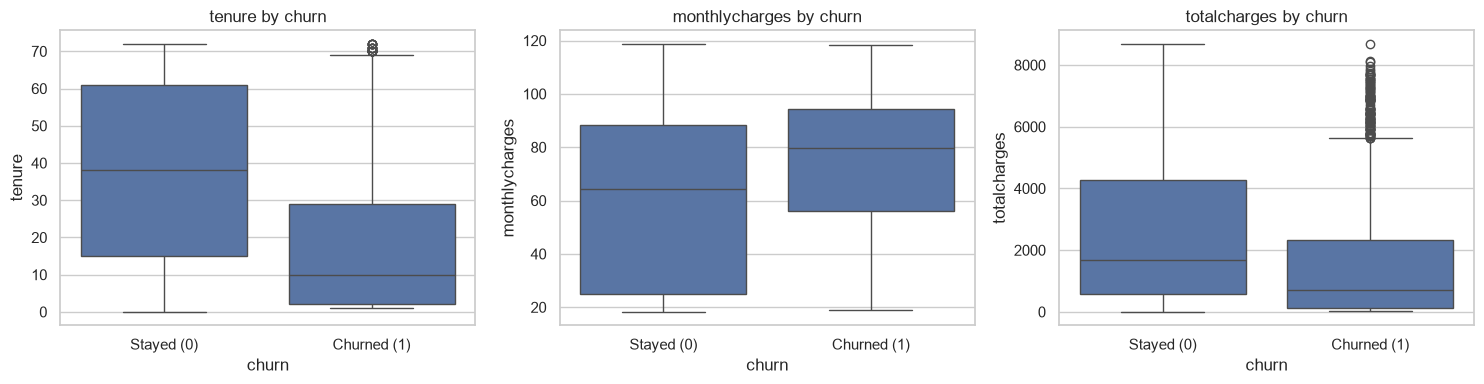

,tenure,monthlycharges,totalcharges
churn,,,
0,38.0,64.43,1679.52
1,10.0,79.65,703.55


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x="churn", y=col, data=df_clean, ax=ax)
    ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

df_clean.groupby("churn")[num_cols].median().round(2)

**Finding.** Median tenure is 10 months for churned customers versus 38 for those who stayed. Churned customers pay more per month (median 79.65 versus 64.43) but have a lower total spent (703.55 versus 1,679.52) because they left early. Total charges has several high outliers among churned customers, i.e. some long-tenure, high-bill customers also leave.

**Churn versus non-churn proportions** as counts and as a pie chart.

         customers  percent
churn                      
Stayed        5174     73.5
Churned       1869     26.5


C:\Users\User\AppData\Local\Temp\ipykernel_20688\397337598.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Stayed", "Churned"])


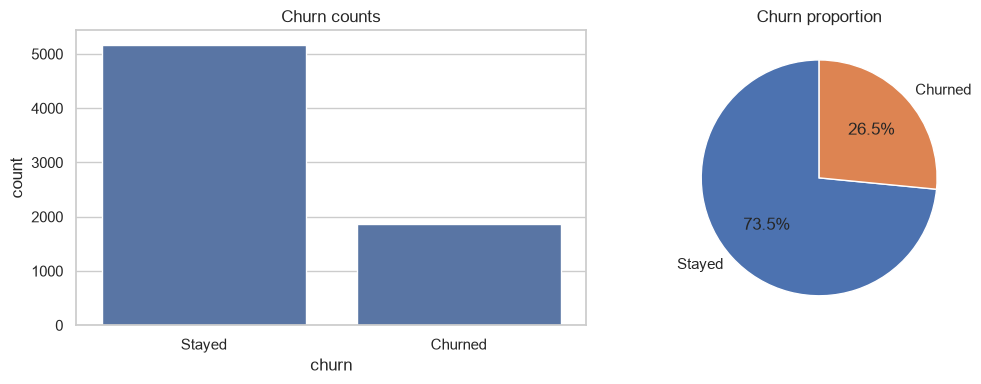

In [22]:
counts = df_clean["churn"].value_counts().rename({0: "Stayed", 1: "Churned"})
percent = (df_clean["churn"].value_counts(normalize=True) * 100).round(1).rename({0: "Stayed", 1: "Churned"})
print(pd.DataFrame({"customers": counts, "percent": percent}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="churn", data=df_clean, ax=axes[0])
axes[0].set_xticklabels(["Stayed", "Churned"])
axes[0].set_title("Churn counts")
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Churn proportion")
plt.tight_layout()
plt.show()

**Finding.** 26.5% of customers churned (1,869 of 7,043), roughly one in four. The 73.5% / 26.5% split is imbalanced.

**Churn rate by key categories** (mean of the 0/1 churn column per group). This is a first look at where churn is concentrated.

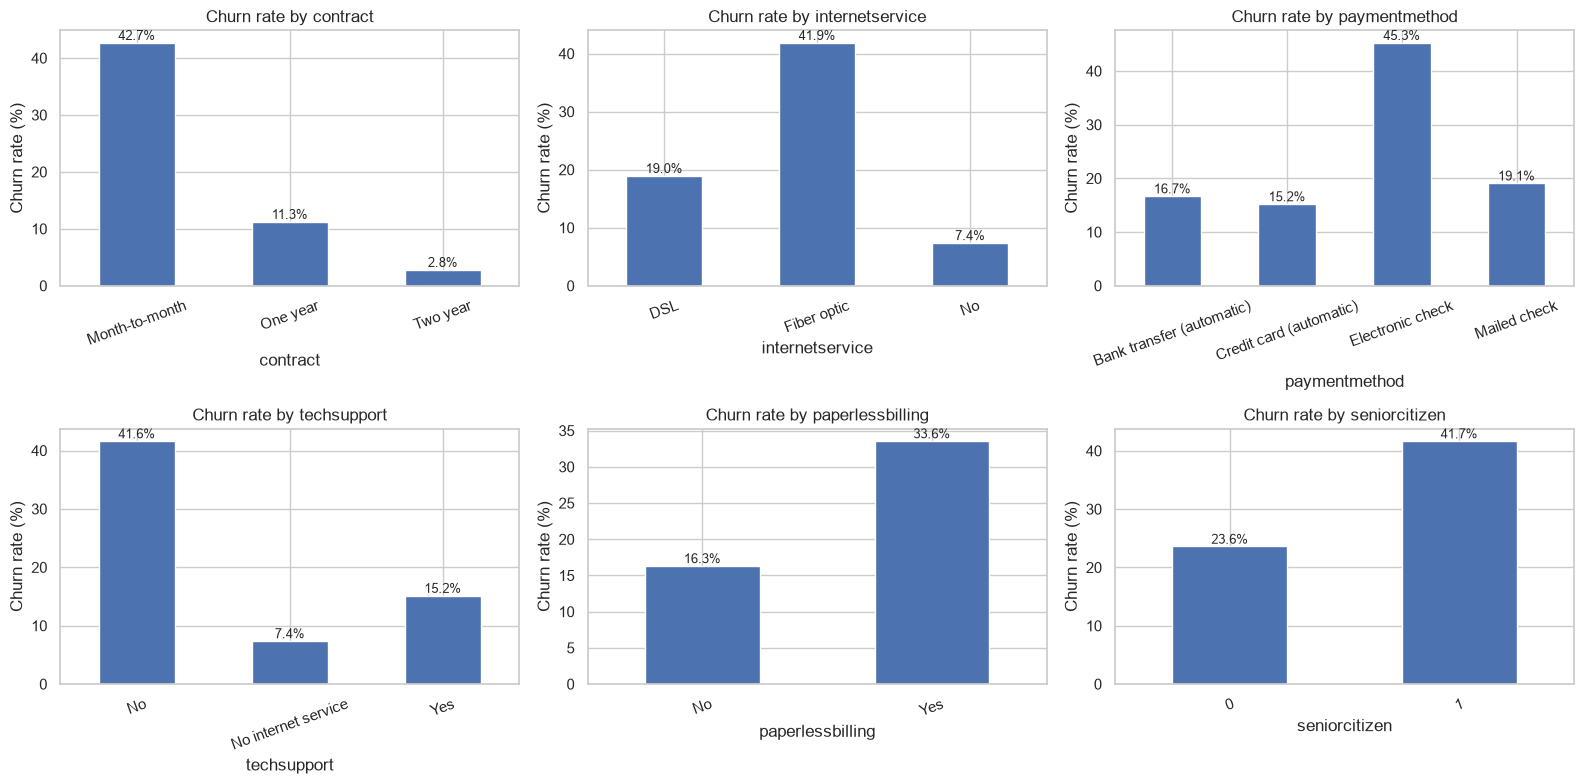

In [23]:
cols = ["contract", "internetservice", "paymentmethod", "techsupport", "paperlessbilling", "seniorcitizen"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, cols):
    rate = df_clean.groupby(col)["churn"].mean() * 100
    rate.plot(kind="bar", ax=ax, rot=20)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(f"Churn rate by {col}")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

**Finding.** Highest churn: month-to-month contracts (42.7%), fiber optic internet (41.9%), electronic check payment (45.3%), no tech support (41.6%), paperless billing (33.6%), senior citizens (41.7%). Lowest: two-year contracts (2.8%) and customers without internet service (7.4%).

**Churn rate by four tenure bands**, to see how churn changes as customers stay longer.

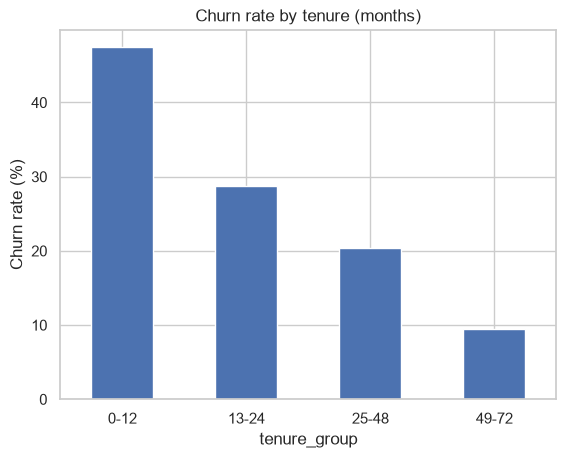

tenure_group
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: churn, dtype: float64

In [24]:
df_clean["tenure_group"] = pd.cut(df_clean["tenure"], bins=[-1, 12, 24, 48, 72],
                                  labels=["0-12", "13-24", "25-48", "49-72"])
rate = df_clean.groupby("tenure_group", observed=True)["churn"].mean() * 100
rate.plot(kind="bar", rot=0, title="Churn rate by tenure (months)")
plt.ylabel("Churn rate (%)")
plt.show()
rate.round(1)

**Finding.** Churn falls steadily with tenure: 47.4% (0-12 months), 28.7% (13-24), 20.4% (25-48), 9.5% (49-72).

**Correlation matrix** of the numeric columns and churn.

In [ ]:
sns.heatmap(df_clean[num_cols + ["seniorcitizen", "churn"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

**Finding.** Tenure has the strongest link with churn (-0.35: longer tenure, less churn). Monthly charges (+0.19) and senior citizen status (+0.15) are weakly positive. `tenure` and `totalcharges` are highly correlated (0.83), so they carry overlapping information; keep this in mind when building models. Correlation does not prove cause.

## 4. Customer segmentation visualization (Task 4)

Goal: split customers into tenure segments (0-12, 13-36, 37+ months), show how the customer base is distributed, and compare average monthly charges across segments.

**Create the segments.** `bins=[-1, 12, 36, 72]` makes the first segment include tenure 0, so none of the 11 new customers is left out.

In [ ]:
sns.set_theme(style="whitegrid")

df_clean["tenure_segment"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 36, 72],
    labels=["0-12 months", "13-36 months", "37+ months"]
)

seg_counts = df_clean["tenure_segment"].value_counts().sort_index()
seg_pct = (seg_counts / seg_counts.sum() * 100).round(1)
print(pd.DataFrame({"customers": seg_counts, "percent": seg_pct}))

**Finding.** 31.0% of customers are in their first year (2,186), 26.4% are 13-36 months (1,856) and 42.6% have 37+ months (3,001). The segment counts add up to 7,043.

**Pie chart** of customers by tenure segment.

In [ ]:
colors = ["#4C78A8", "#F58518", "#54A24B"]
plt.figure(figsize=(6, 6))
plt.pie(seg_counts, labels=seg_counts.index, autopct="%1.1f%%", startangle=90,
        colors=colors, wedgeprops={"edgecolor": "white"})
plt.title("Customer distribution by tenure")
plt.show()

**Donut chart** of the same data, with the total in the centre. Either chart satisfies the task; the donut is the cleaner version.

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(seg_counts, labels=seg_counts.index, autopct="%1.1f%%", startangle=90,
       colors=colors, pctdistance=0.8,
       wedgeprops={"width": 0.4, "edgecolor": "white"})
ax.text(0, 0, f"{seg_counts.sum():,}\ncustomers", ha="center", va="center",
        fontsize=14, fontweight="bold")
ax.set_title("Customer distribution by tenure")
plt.show()

**Average monthly charges** for each segment, split by stayed versus churned. This table feeds the clustered bar chart.

In [ ]:
avg = (df_clean.groupby(["tenure_segment", "churn"], observed=True)["monthlycharges"]
       .mean().round(2).unstack())
avg.columns = ["Stayed", "Churned"]
print(avg)

**Clustered bar chart** with value labels. The annotation is calculated from the data and points at the segment with the largest gap between churned and stayed customers.

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
avg.plot(kind="bar", ax=ax, color=["#4C78A8", "#E45756"], width=0.75, rot=0)

# value labels on every bar
for p in ax.patches:
    ax.annotate(f"${p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10, fontweight="bold")

# highlight the biggest gap between churned and stayed
gap = (avg["Churned"] - avg["Stayed"])
biggest = gap.abs().idxmax()
pos = list(avg.index).index(biggest)
top = avg.loc[biggest].max()
ax.annotate(f"Largest gap: {gap[biggest]:+.2f} USD\n(churned vs stayed)",
            xy=(pos, top), xytext=(pos, top + 12),
            ha="center", fontsize=10, color="black",
            arrowprops=dict(arrowstyle="->", color="black"),
            bbox=dict(boxstyle="round", fc="#FFF4DC", ec="#B7791F"))

ax.set_ylim(0, avg.values.max() + 25)
ax.set_ylabel("Average monthly charges")
ax.set_xlabel("Tenure segment")
ax.set_title("Average monthly charges by tenure segment and churn status")
ax.legend(title="Customer status")
plt.tight_layout()
plt.show()

**Finding.** Churned customers pay more per month than those who stayed in every segment: +19.78 (0-12 months), **+23.44 (13-36 months, the largest gap)** and +19.50 (37+ months). Monthly charges also rise with tenure for both groups.

Overall average monthly charges per segment, regardless of churn.

In [ ]:
overall = df_clean.groupby("tenure_segment", observed=True)["monthlycharges"].mean().round(2)
print(overall)

**Finding.** Average monthly charges rise with tenure: 56.10, 63.25 and 72.01. Longer-tenure customers have moved to higher-value plans.

Churn rate per tenure segment.

In [ ]:
churn_rate = (df_clean.groupby("tenure_segment", observed=True)["churn"].mean() * 100).round(1)
print(churn_rate)

**Finding.** Churn falls sharply with tenure: 47.4% (0-12 months), 25.5% (13-36) and 11.9% (37+). The first year is the highest-risk stage.

## 5. Advanced analysis (Task 5)

Goal: go deeper by grouping customers by tenure and comparing churn across demographics, payment methods, contract types and lifecycle stages.

The next cell recreates `tenure_segment` so this section can be re-run on its own; it gives the same result as Section 4.

In [ ]:
df_clean["tenure_segment"] = pd.cut(df_clean["tenure"], bins=[-1, 12, 36, 72],
                                    labels=["0-12 months", "13-36 months", "37+ months"])

**Statistics by tenure group:** customers, churn rate, and the mean and median of monthly and total charges.

In [ ]:
tenure_stats = df_clean.groupby("tenure_segment", observed=True).agg(
    customers=("churn", "size"),
    churn_rate_pct=("churn", lambda s: round(s.mean() * 100, 1)),
    avg_monthly=("monthlycharges", "mean"),
    median_monthly=("monthlycharges", "median"),
    avg_total=("totalcharges", "mean"),
    median_total=("totalcharges", "median"),
    std_monthly=("monthlycharges", "std"),
).round(2)
tenure_stats

**Finding.** The first-year group is the largest churn problem: 47.4% churn on the lowest average bill (56.10). The 37+ group has 11.9% churn on the highest bill (72.01) and a median total spend of 4,282.

Helper function: churn count and churn rate for any column, sorted from highest to lowest.

In [ ]:
def churn_by(col, order=None):
    t = df_clean.groupby(col, observed=True)["churn"].agg(customers="size", churned="sum", rate="mean")
    t["churn_rate_pct"] = (t["rate"] * 100).round(1)
    t = t.drop(columns="rate")
    return t.sort_values("churn_rate_pct", ascending=False)

**Churn by demographics:** gender, senior citizen status, partner and dependents.

In [ ]:
df_clean["senior_label"] = df_clean["seniorcitizen"].map({0: "Not senior", 1: "Senior"})

for col in ["gender", "senior_label", "partner", "dependents"]:
    print(f"\n--- Churn by {col} ---")
    print(churn_by(col))

**Finding.** Gender makes almost no difference (26.9% female, 26.2% male). Senior citizens churn far more (41.7% versus 23.6%). Customers without a partner churn at 33.0% versus 19.7%, and without dependents at 31.3% versus 15.5%.

**Churn by payment method and contract type.**

In [ ]:
print("--- Churn by payment method ---")
print(churn_by("paymentmethod"))
print("\n--- Churn by contract ---")
print(churn_by("contract"))

**Finding.** Electronic check users churn at 45.3% versus 15.2-19.1% for all other methods. Month-to-month contracts churn at 42.7% versus 11.3% (one year) and 2.8% (two year). Month-to-month customers are 3,875 of 7,043 (55%) yet account for 1,655 of the 1,869 churners (about 89%).

Chart of churn rate by demographics. The red dashed line is the overall churn rate (26.5%).

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, col in zip(axes, ["gender", "senior_label", "partner", "dependents"]):
    rate = df_clean.groupby(col)["churn"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="#4C78A8", rot=0)
    ax.axhline(df_clean["churn"].mean() * 100, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

Chart of churn rate by payment method and contract. The dashed line is the overall churn rate.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, ["paymentmethod", "contract"]):
    rate = (df_clean.groupby(col)["churn"].mean() * 100).sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="#E45756", rot=15)
    ax.axhline(df_clean["churn"].mean() * 100, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

**Heatmap of churn rate by contract type and tenure group.** This tests whether the contract effect holds at every lifecycle stage.

In [ ]:
pivot = (df_clean.pivot_table(index="contract", columns="tenure_segment",
                              values="churn", aggfunc="mean", observed=True) * 100).round(1)
plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"})
plt.title("Churn rate (%) by contract type and tenure group")
plt.show()

**Finding.** Yes. Month-to-month churn is 51.4% / 35.7% / 29.6% across the three stages, one-year is 10.5% / 8.1% / 13.0%, and two-year is 0.0% / 1.1% / 3.2%. Even long-tenure month-to-month customers (29.6%) churn more than brand-new one-year customers (10.5%), so contract type matters beyond tenure.

**Lifecycle trend.** The dataset has no calendar dates, so a true time series is not possible. Tenure is used as the timeline: each point is "customers who are N months into their relationship". Dotted lines mark the stage boundaries at 12 and 36 months.

In [ ]:
monthly = df_clean[df_clean["tenure"] > 0].groupby("tenure").agg(
    churn_rate=("churn", lambda s: s.mean() * 100),
    customers=("churn", "size"),
    avg_monthly=("monthlycharges", "mean"),
)
monthly["churn_smooth"] = monthly["churn_rate"].rolling(3, center=True).mean()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(monthly.index, monthly["churn_rate"], alpha=0.35, color="#E45756", label="Churn rate (raw)")
ax1.plot(monthly.index, monthly["churn_smooth"], color="#E45756", linewidth=2.5, label="Churn rate (3-month average)")
ax1.set_xlabel("Tenure (months)")
ax1.set_ylabel("Churn rate (%)", color="#E45756")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["avg_monthly"], color="#4C78A8", linewidth=1.8, label="Avg monthly charges")
ax2.set_ylabel("Average monthly charges", color="#4C78A8")
ax2.grid(False)
for stage_end in [12, 36]:
    ax1.axvline(stage_end, color="grey", linestyle=":")
ax1.set_title("Customer lifecycle: churn rate and average monthly charges by tenure month")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
plt.tight_layout()
plt.show()

**Finding.** Churn is highest in the first months (about 60% at month 1), drops to roughly 33% by month 12, about 20% around month 36 and below 10% beyond about month 62. Average monthly charges drift upward as tenure grows (from about 50 to about 80).

**Cumulative churn by tenure (approximation).** This plots the share of *all* customers who have not churned up to each tenure month. It is a rough illustration, not a formal survival analysis (that would need churn dates).

In [ ]:
surv = df_clean.groupby("tenure")["churn"].agg(["size", "sum"])
surv["retained_pct"] = 100 - (surv["sum"].cumsum() / surv["size"].sum() * 100)
plt.figure(figsize=(10, 4))
plt.plot(surv.index, surv["retained_pct"])
plt.title("Cumulative share of customers who have not churned, by tenure")
plt.xlabel("Tenure (months)"); plt.ylabel("Not churned (%)")
plt.show()

**Finding.** The curve falls fastest in the first months and flattens later. By month 12 about 14.5% of all customers have already churned, which is more than half of all churners (26.5% of customers in total).

**Significance test (chi-square).** Tests whether the churn difference between groups is real or could be chance. A p-value below 0.05 is treated as significant. Requires `scipy`.

In [ ]:
from scipy.stats import chi2_contingency
for col in ["gender", "senior_label", "paymentmethod", "contract"]:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df_clean[col], df_clean["churn"]))
    print(f"{col:15s} p-value = {p:.4g}  ->", "significant" if p < 0.05 else "not significant")

**Finding.** Gender is **not** significant (p = 0.49). Senior citizen status, payment method and contract type are all highly significant (p far below 0.05). Partner and dependents were not tested here, but their gaps (13-16 percentage points) are large.

## 6. Summary of findings

1. **26.5% of customers churned** (1,869 of 7,043).
2. **Tenure is the strongest driver.** Churn falls from 47.4% in the first year to 11.9% after 37 months.
3. **Contract type is the strongest category driver.** Month-to-month is 42.7% versus 2.8% for two-year contracts, and the effect holds at every tenure stage.
4. **Electronic check payers churn at 45.3%**, versus 15-19% for every other payment method.
5. **Fiber optic customers (41.9%), senior citizens (41.7%) and customers without tech support (41.6%)** are other high-risk groups.
6. **Gender is not a factor** (26.9% versus 26.2%, p = 0.49).
7. **Churned customers pay more per month** than those who stayed in every tenure segment (gap of about 20-23).

**Recommendations** (full detail in the accompanying report): strengthen first-year onboarding, move month-to-month customers to longer contracts, move electronic check users to automatic payment, review fiber optic service and price, and add support offers for senior citizens and customers without tech support.

**Limitations.** The data is a single snapshot with no dates, so patterns are associations, not proven causes. Groups overlap (for example month-to-month customers are also often electronic-check payers), so a predictive model is the next step to separate their effects.